In [8]:
import os

# Define the paths for each mathematical symbol's images
# Each symbol now maps to a list of directories to allow combining classes
paths = {
    'suma': ['/content/drive/MyDrive/proyecto simbolos/suma'],
    'resta': ['/content/drive/MyDrive/proyecto simbolos/resta'],
    'multiplicacion': ['/content/drive/MyDrive/proyecto simbolos/mult asterisco', '/content/drive/MyDrive/proyecto simbolos/mult x'],
    'division': ['/content/drive/MyDrive/proyecto simbolos/div']
}

# Verify that the paths exist (optional, but good practice)
for symbol, dir_list in paths.items():
    print(f"Checking paths for '{symbol}':")
    for path in dir_list:
        if not os.path.isdir(path):
            print(f"Warning: The directory for '{symbol}' does not exist: {path}")
        else:
            print(f"Path for '{symbol}': {path}")

print("Please update the 'paths' dictionary with the correct directories before proceeding.")

Checking paths for 'suma':
Path for 'suma': /content/drive/MyDrive/proyecto simbolos/suma
Checking paths for 'resta':
Path for 'resta': /content/drive/MyDrive/proyecto simbolos/resta
Checking paths for 'multiplicacion':
Path for 'multiplicacion': /content/drive/MyDrive/proyecto simbolos/mult asterisco
Path for 'multiplicacion': /content/drive/MyDrive/proyecto simbolos/mult x
Checking paths for 'division':
Path for 'division': /content/drive/MyDrive/proyecto simbolos/div
Please update the 'paths' dictionary with the correct directories before proceeding.


Starting image loading and preprocessing...
Processing symbol 'suma' (label: 0)...
Loaded 340 images from '/content/drive/MyDrive/proyecto simbolos/suma'.
Finished loading 340 images for combined symbol 'suma'.
Processing symbol 'resta' (label: 1)...
Loaded 340 images from '/content/drive/MyDrive/proyecto simbolos/resta'.
Finished loading 340 images for combined symbol 'resta'.
Processing symbol 'multiplicacion' (label: 2)...
Loaded 340 images from '/content/drive/MyDrive/proyecto simbolos/mult asterisco'.
Loaded 340 images from '/content/drive/MyDrive/proyecto simbolos/mult x'.
Finished loading 680 images for combined symbol 'multiplicacion'.
Processing symbol 'division' (label: 3)...
Loaded 340 images from '/content/drive/MyDrive/proyecto simbolos/div'.
Finished loading 340 images for combined symbol 'division'.
Finished loading 1700 total images.
Total images loaded: 1700
Image shape after preprocessing: (28, 28)
Labels unique values: [0 1 2 3]
Class names: ['suma', 'resta', 'multip

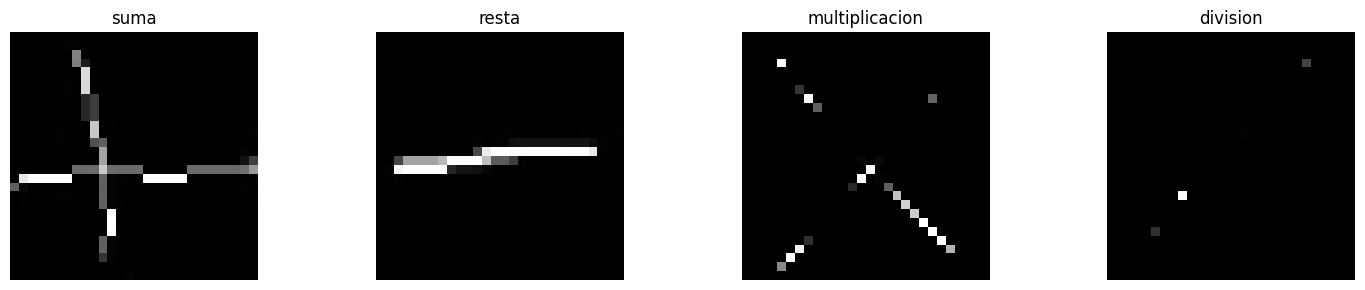

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt # Added this import

# Desired image size for uniformity
IMG_SIZE = (28, 28) # Example size, can be adjusted

def load_and_preprocess_images(paths, img_size):
    all_images = []
    all_labels = []
    # label_map will now use the new combined class names
    label_map = {symbol: i for i, symbol in enumerate(paths.keys())}

    print("Starting image loading and preprocessing...")
    for symbol, dir_list in paths.items(): # dir_list is now a list of directories for the current symbol
        label = label_map[symbol]
        total_loaded_for_symbol = 0

        print(f"Processing symbol '{symbol}' (label: {label})...")
        for path in dir_list: # Iterate through each directory for the current symbol
            if not os.path.isdir(path):
                print(f"Skipping directory '{path}' for symbol '{symbol}': Directory not found.")
                continue

            image_files = [os.path.join(path, f) for f in os.listdir(path) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp'))]

            loaded_count_for_dir = 0 # To count images actually loaded for this specific directory

            for img_file in image_files:
                img = cv2.imread(img_file, cv2.IMREAD_GRAYSCALE) # Load as grayscale for simplicity
                if img is not None:
                    img_resized = cv2.resize(img, img_size) # Resize image
                    # Invertir colores si es necesario (para que el fondo sea 0 y el trazo sea valor alto)
                    img_invert= cv2.bitwise_not(img_resized)
                    img_normalized = img_invert / 255.0 # Normalize pixel values to 0-1
                    all_images.append(img_normalized)
                    all_labels.append(label)
                    loaded_count_for_dir += 1
                else:
                    print(f"Error: Could not load image {img_file}")

            total_loaded_for_symbol += loaded_count_for_dir
            print(f"Loaded {loaded_count_for_dir} images from '{path}'.")

        print(f"Finished loading {total_loaded_for_symbol} images for combined symbol '{symbol}'.")


    print(f"Finished loading {len(all_images)} total images.")
    # The class_names list should reflect the new combined classes
    return np.array(all_images), np.array(all_labels), list(paths.keys())

# Load and preprocess the images
X, y, class_names = load_and_preprocess_images(paths, IMG_SIZE)

print(f"Total images loaded: {len(X)}")
print(f"Image shape after preprocessing: {X.shape[1:]}")
print(f"Labels unique values: {np.unique(y)}")
print(f"Class names: {class_names}")

# Reshape X for SVM if necessary (flatten images)
X_flattened = X.reshape(len(X), -1)
print(f"Flattened image data shape: {X_flattened.shape}")

# --- Added visualization code based on user request ---
print("\nDisplaying one random image from each class:")
plt.figure(figsize=(15, 3))
for i, class_name in enumerate(class_names):
    class_indices = np.where(y == i)[0]
    if len(class_indices) > 0:
        img_index = np.random.choice(class_indices)
        plt.subplot(1, len(class_names), i + 1)
        plt.imshow(X[img_index], cmap='gray') # Display preprocessed image directly with grayscale colormap
        plt.title(class_name)
        plt.axis('off')
plt.tight_layout()
plt.show()

## Split Data

### Subtask:
Split the flattened image data (X_flattened) and labels (y) into training and testing sets. This will prepare the data for model training and unbiased evaluation.


**Reasoning**:
The subtask requires splitting the data into training and testing sets using `train_test_split` and printing the shapes of the resulting sets. This code block will perform these actions.



In [10]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_flattened, y, test_size=0.20, random_state=42)

# Print the shapes of the resulting sets
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (1360, 784)
y_train shape: (1360,)
X_test shape: (340, 784)
y_test shape: (340,)


## Define SVM Model and GridSearchCV Parameters

### Subtask:
Import the `SVC` model from `sklearn.svm` and `GridSearchCV` from `sklearn.model_selection`. Define a parameter grid (`param_grid`) to explore different SVM kernels (e.g., 'linear', 'rbf') and their respective hyperparameters (e.g., 'C' for regularization, 'gamma' for 'rbf' kernel) for `GridSearchCV`.


**Reasoning**:
The subtask requires importing `SVC` and `GridSearchCV`, initializing the `SVC` model, and defining the `param_grid` for hyperparameter tuning as per the instructions.



In [11]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# Initialize the SVM classifier
svm = SVC(probability=True, random_state=42)

# Define the parameter grid for GridSearchCV
param_grid = [
    {'kernel': ['linear'], 'C': [0.1, 1, 10]},
    {'kernel': ['rbf'], 'C': [0.1, 1, 10], 'gamma': ["scale","auto"]}
]

print("SVC model and GridSearchCV parameters defined.")

SVC model and GridSearchCV parameters defined.


In [12]:
print("\nStarting GridSearchCV to find the best SVM hyperparameters...")
grid_search = GridSearchCV(svm, param_grid, cv=3, scoring='accuracy', n_jobs=-1, verbose=2)
grid_search.fit(X_train, y_train)

print("GridSearchCV completed.")


Starting GridSearchCV to find the best SVM hyperparameters...
Fitting 3 folds for each of 9 candidates, totalling 27 fits
GridSearchCV completed.


In [13]:
best_svm = grid_search.best_estimator_
print(f"\nBest parameters found by GridSearchCV: {grid_search.best_params_}")
print(f"Best cross-validation accuracy: {grid_search.best_score_:.4f}")

print("Best SVM model details extracted.")


Best parameters found by GridSearchCV: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best cross-validation accuracy: 0.8882
Best SVM model details extracted.



Evaluating the best SVM model on the test set...
Test Accuracy: 0.9088

Classification Report:
                precision    recall  f1-score   support

          suma       0.97      0.84      0.90        67
         resta       0.96      0.87      0.91        79
multiplicacion       0.95      0.93      0.94       131
      division       0.77      0.98      0.86        63

      accuracy                           0.91       340
     macro avg       0.91      0.91      0.90       340
  weighted avg       0.92      0.91      0.91       340



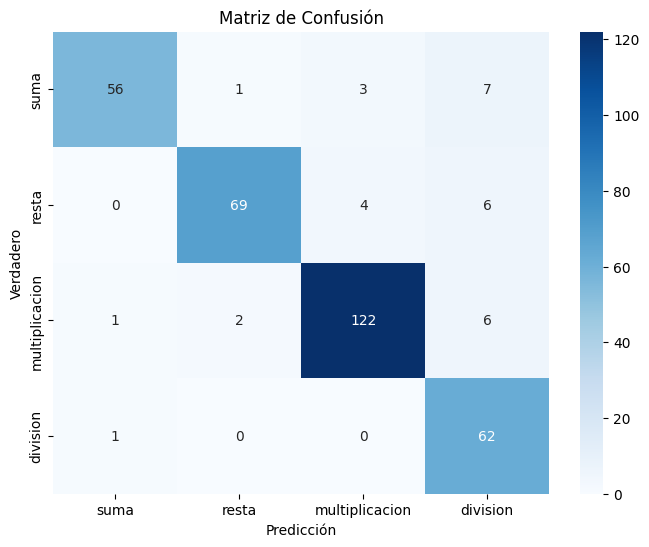

Model evaluation completed.


In [15]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("\nEvaluating the best SVM model on the test set...")
y_pred = best_svm.predict(X_test)

# Calculate and print accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.4f}")

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))


# Visualize confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Verdadero')
plt.show()

print("Model evaluation completed.")

```markdown
## Red Neuronal Convolucional (CNN)

### Paso 1: Preparación de Datos
A diferencia de SVM que requiere los datos aplanados, una CNN necesita mantener la estructura espacial de las imágenes. Por ello, daremos formato a nuestros conjuntos de datos para que tengan la forma `(muestras, 28, 28, 1)`, indicando un solo canal de color (escala de grises).
```

In [22]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Redimensionar los conjuntos de datos para la CNN (añadir dimensión de canal de color)
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

print(f"Forma de X_train para CNN: {X_train_cnn.shape}")
print(f"Forma de X_test para CNN: {X_test_cnn.shape}")

Forma de X_train para CNN: (1360, 28, 28, 1)
Forma de X_test para CNN: (340, 28, 28, 1)


```markdown
### Paso 2: Construcción de la Arquitectura CNN
Diseñaremos una red secuencial con capas convolucionales para extraer características visuales, capas de Max-Pooling para reducir la dimensionalidad espacial, Dropout para prevenir el sobreajuste (overfitting) y finalmente capas densas para la clasificación de los 4 símbolos.
```

In [23]:
model_cnn = models.Sequential([
    # Primera capa convolucional
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    # Segunda capa convolucional
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Tercera capa convolucional
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Aplanar las características para conectar con las capas densas
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    # Capa de salida con activación Softmax para la clasificación multiclase (4 clases)
    layers.Dense(4, activation='softmax')
])

model_cnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 92,932 (363.02 KB)

 Trainable params: 92,932 (363.02 KB)

 Non-trainable params: 0 (0.00 B)

```markdown
### Paso 3: Compilación y Entrenamiento de la CNN
Compilaremos el modelo utilizando el optimizador `adam` y la función de pérdida `sparse_categorical_crossentropy` (adecuada para etiquetas enteras). Entrenaremos la red durante 15 épocas guardando un porcentaje para validación interna.
```

In [24]:
model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Entrenar el modelo
history = model_cnn.fit(
    X_train_cnn, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.15,
    verbose=1
)

Epoch 1/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.6401 - loss: 0.8370 - val_accuracy: 0.9265 - val_loss: 0.2849
Epoch 2/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9178 - loss: 0.2795 - val_accuracy: 0.9167 - val_loss: 0.2324
Epoch 3/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.9351 - loss: 0.2077 - val_accuracy: 0.9461 - val_loss: 0.1389
Epoch 4/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9559 - loss: 0.1490 - val_accuracy: 0.9608 - val_loss: 0.1148
Epoch 5/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9637 - loss: 0.1200 - val_accuracy: 0.9559 - val_loss: 0.1208
Epoch 6/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - accuracy: 0.9766 - loss: 0.0968 - val_accuracy: 0.9608 - val_loss: 0.1282
Epoch 7/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.9602 - loss: 0.1251 - val_accuracy: 0.9608 - val_loss: 0.0986
Epoch 8/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9784 - loss: 0.0757 - val_accuracy: 0.9706 - v

```markdown
### Paso 4: Evaluación de la CNN y Matriz de Confusión
Evaluamos el desempeño de la Red Neuronal Convolucional con el conjunto de pruebas (`X_test_cnn`) y visualizaremos detalladamente su reporte de clasificación junto a su respectiva matriz de confusión.
```

Precisión en el conjunto de prueba (CNN): 0.9529

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Classification Report para CNN:
                precision    recall  f1-score   support

          suma       0.92      0.90      0.91        67
         resta       0.92      0.96      0.94        79
multiplicacion       1.00      0.97      0.98       131
      division       0.94      0.97      0.95        63

      accuracy                           0.95       340
     macro avg       0.94      0.95      0.95       340
  weighted avg       0.95      0.95      0.95       340



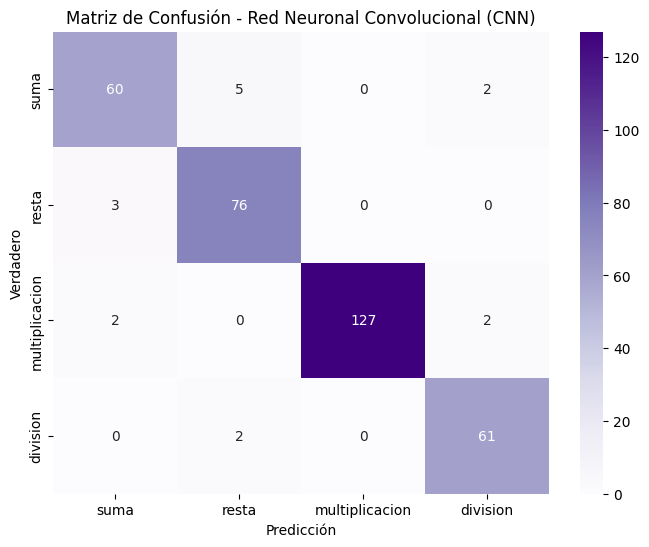

In [25]:
# Evaluar en el conjunto de prueba
test_loss, test_acc = model_cnn.evaluate(X_test_cnn, y_test, verbose=0)
print(f"Precisión en el conjunto de prueba (CNN): {test_acc:.4f}\n")

# Obtener predicciones
y_pred_cnn_probs = model_cnn.predict(X_test_cnn)
y_pred_cnn = np.argmax(y_pred_cnn_probs, axis=1)

# Reporte de clasificación
print("Classification Report para CNN:")
print(classification_report(y_test, y_pred_cnn, target_names=class_names))

# Calcular matriz de confusión
conf_matrix_cnn = confusion_matrix(y_test, y_pred_cnn)

# Visualizar la matriz de confusión
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_cnn, annot=True, fmt='d', cmap='Purples',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusión - Red Neuronal Convolucional (CNN)')
plt.xlabel('Predicción')
plt.ylabel('Verdadero')
plt.show()